# ALTogether: Train에서 판단 기준을 만들고 Frozen에서 사용하기

이 Notebook은 **데이터 → 전처리 → 문서형 학습 → 검토된 문서 고정 → 추론 → 평가** 순서다.
기본 실행은 저장된 실제 출력과 가이드라인을 CPU에서 확인한다. 실제 GPU 실행은 해당 스위치를 직접 켠다.
모델 가중치는 추가 학습하지 않는다. 학습 결과는 이진·후보·최종 선택용 MD 3개다.

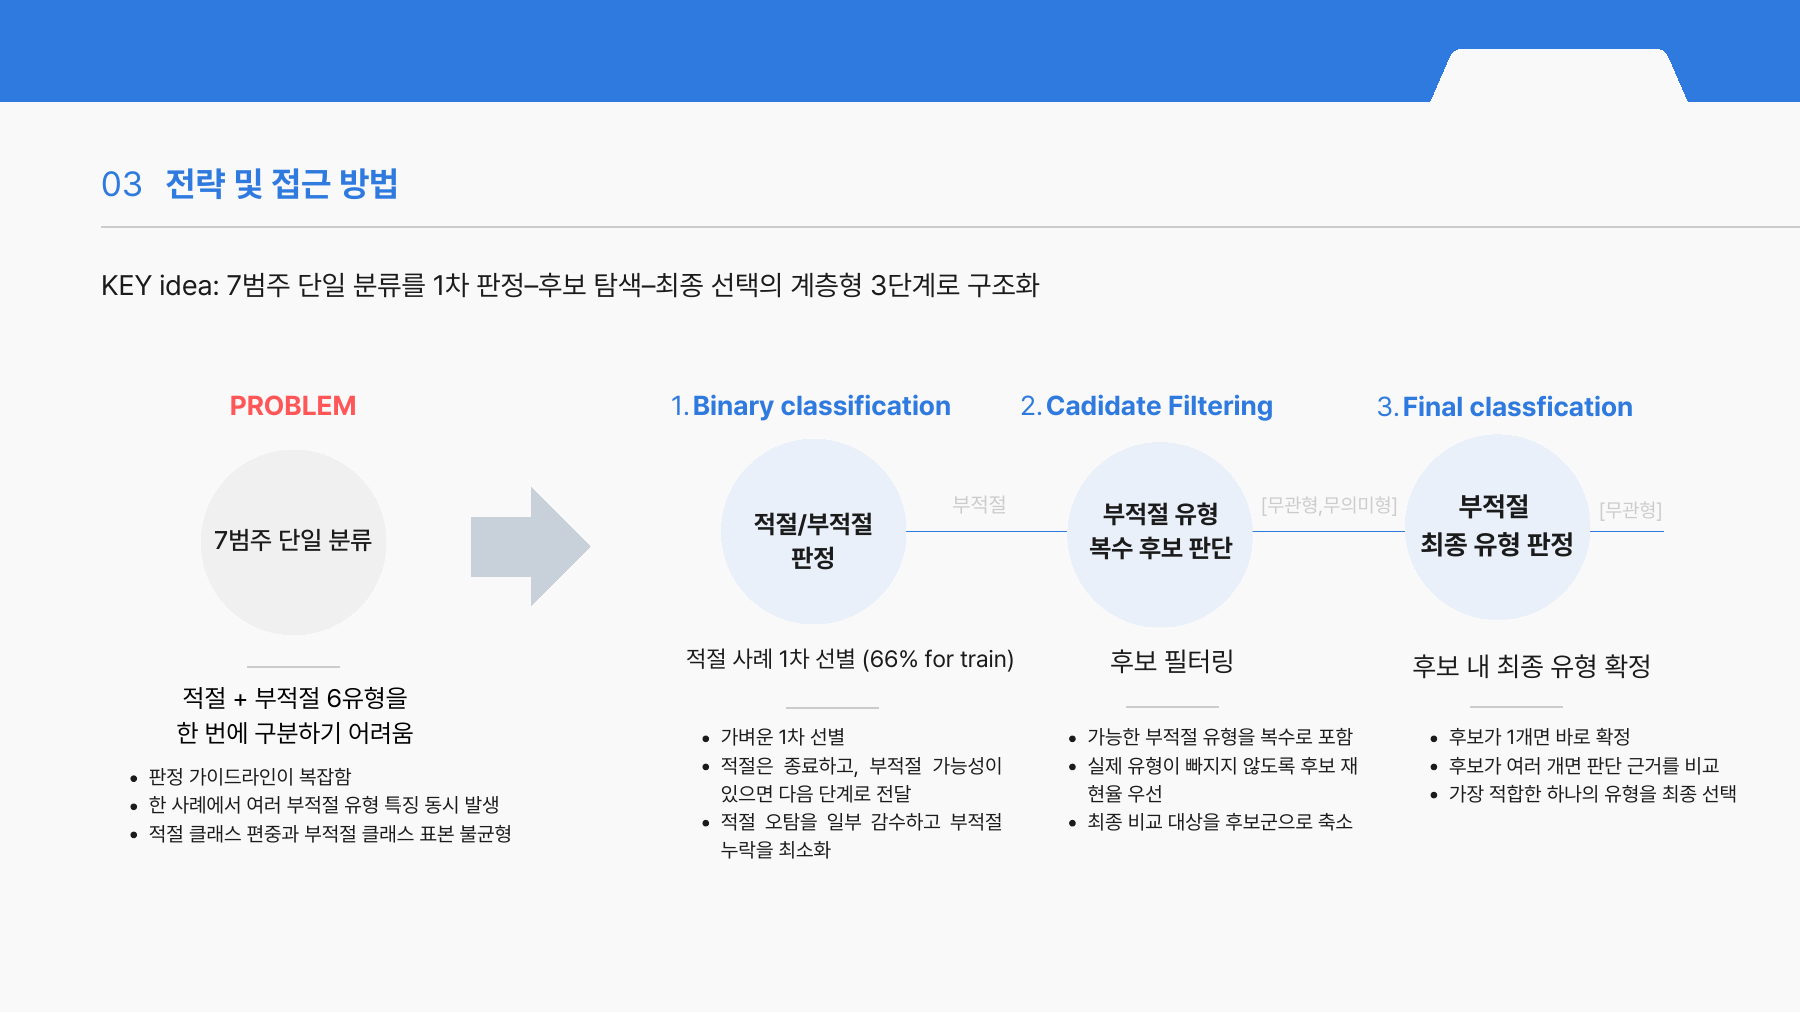

*발표자료 7쪽. 적절성 판단 → 복수 후보 탐색 → 최종 유형 선택으로 문제를 나눈다.*


In [1]:
from pathlib import Path
import json, sys, hashlib
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "model/frozen_config.json").is_file())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]
from common import load_records, resolve_image, prepare_image
from benchmark import score_labels
from evaluate import evaluate
from IPython.display import display, Markdown
print("패키지:", ROOT.name)


패키지: ALTogether_20261106


## 1. 공식 데이터 확인
Train 정답은 학습 단계에서만 사용한다. Test 전체 정답은 공개되지 않았다. 공개 109건은 별도의 재확인 평가로 다룬다.

In [2]:
from collections import Counter
train = load_records(ROOT / "data/train")
test = load_records(ROOT / "data/test")
assert len(train) == 2400 and len(test) == 600
print("Train:", len(train), "Test:", len(test))
print("Train 유형별 개수:", dict(Counter(r["label"] for r in train)))
print("입력 필드:", list(test[0]))


Train: 2400 Test: 600
Train 유형별 개수: {'무관형': 15, '불충분형': 564, '적절': 1599, '중복형': 146, '파일명형': 26, '무의미형': 24, '장식오용형': 26}
입력 필드: ['record_id', 'page_url', 'page_title', 'kogl_marker', 'image_url', 'image_file', 'alt_text', 'context_text', 'in_link', 'link_dest', 'heading_path']


## 2. 이미지 전처리
SVG 래스터화, 첫 프레임 선택, 투명 이미지 합성. 흰 전경이 소실될 때만 밝은 회색을 적용한다. 원본 메타데이터와 처리 내역을 함께 확인한다.

In [3]:
row = test[0]
image, preprocessing = prepare_image(resolve_image(ROOT / "data/test", row), "auto_gray")
display(image)
print("alt:", row["alt_text"])
print("문맥:", row["context_text"])
print("전처리:", preprocessing)


alt: 닫기
문맥: QR코드 현재 페이지의 QR코드 입니다. 주소복사 스크랩 인쇄 공유 X 페이스북
전처리: {'format': 'PNG', 'source_size': [12, 12], 'frames': 1, 'frame_index': 0, 'background': 'white', 'exif_applied': False, 'decoder': 'pillow', 'has_transparency': True, 'requested_background': 'auto_gray', 'background_rgb': [255, 255, 255], 'background_adjusted': False}


## 3. Train: 오류 사례 → 피드백 → 재판정·MD 갱신
공개 정답과 최초 판단이 다른 이진 사례, 정답 후보가 누락된 후보 사례, 정답이 후보 안에 있는데 최종 선택이 틀린 사례만 갱신 대상이다.
피드백은 원본·최초 결과·공식 기준·현재 MD·공개 정답으로 만들고, 문서 갱신은 기존 MD와 새 피드백으로 수행한다.
다음은 **과거 실제 Train 실행의 저장 결과**이며 이 셀에서 새로 추론한 값은 아니다.

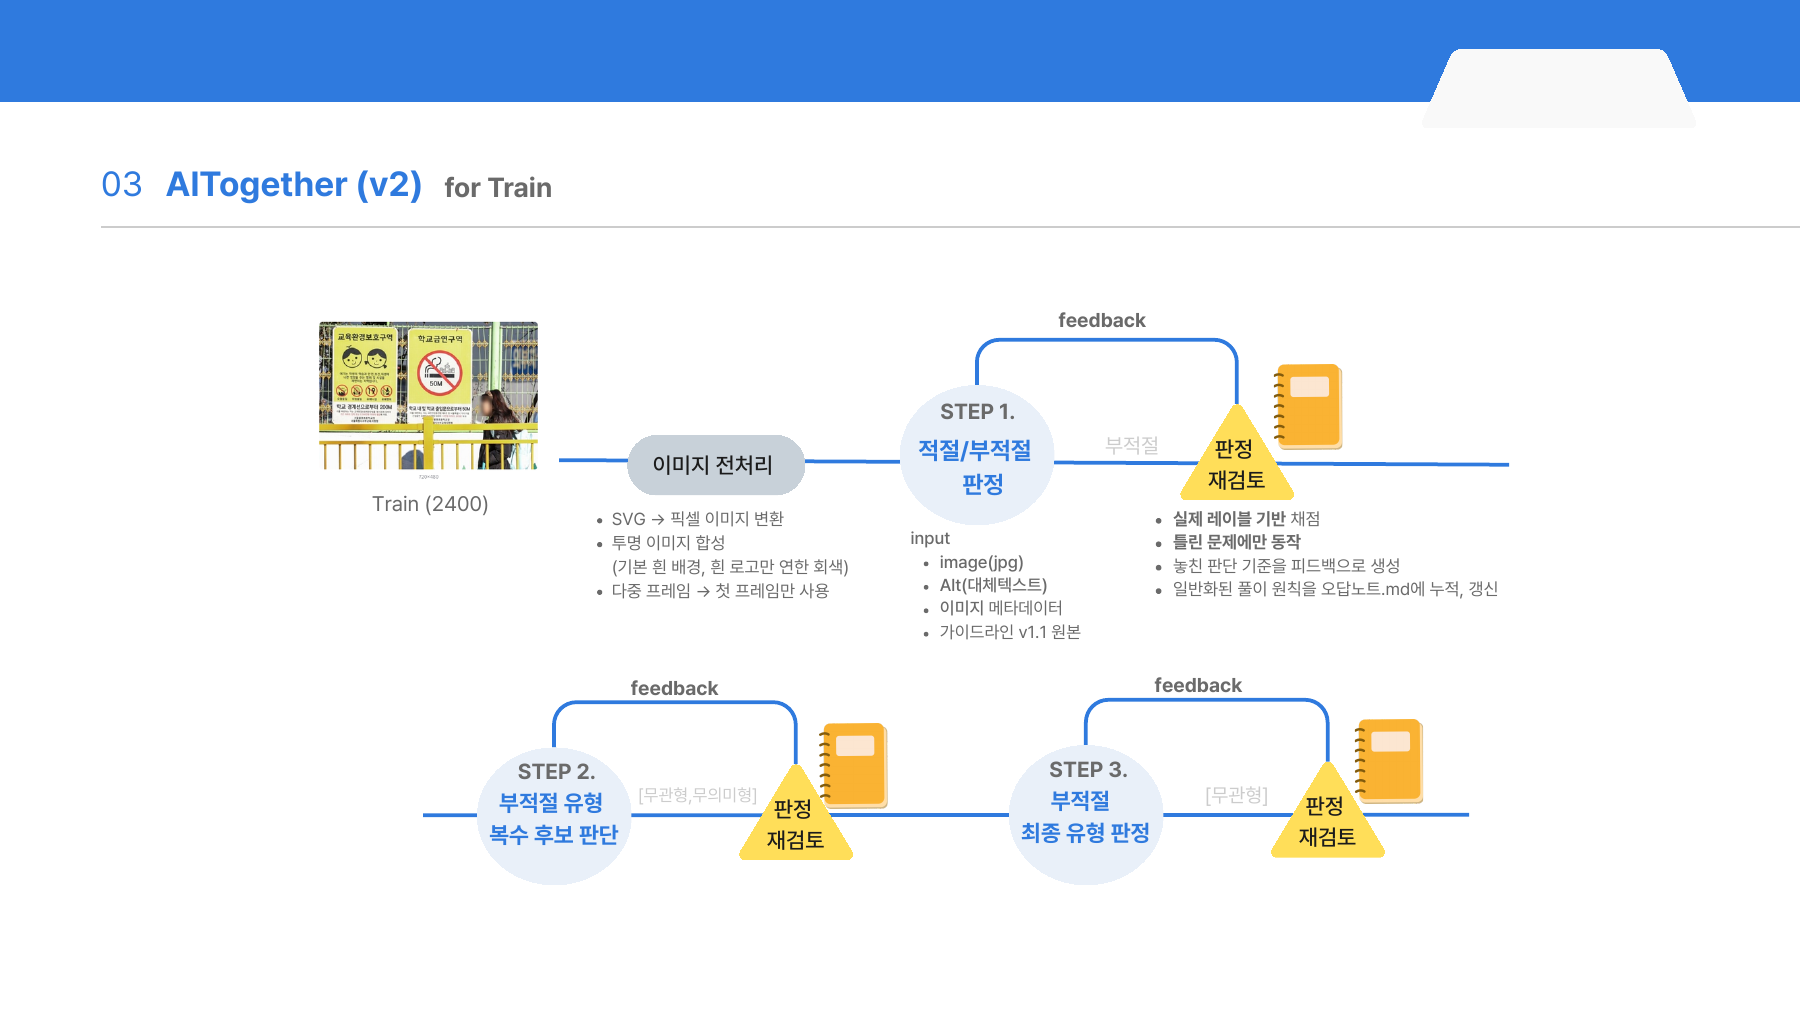

*발표자료 10쪽. 단계별 실패 사례에서 피드백을 생성하고, 재판정과 함께 해당 단계의 가이드라인을 갱신한다.*


In [4]:
examples = json.loads((ROOT / "demo/examples.json").read_text(encoding="utf-8"))
example = next(e for e in examples if e["mode"] == "Train")
print("기록 출처:", example["source_run"])
display(Markdown("**대체텍스트:** " + (example["record"]["alt_text"] or "(빈 값)")))
for key in ("binary_decision", "reflection_feedback", "reflection_decision", "reflection_document_status"):
    print(key, json.dumps(example["result"].get(key), ensure_ascii=False, indent=2))


기록 출처: 20261017_031728_7a4451


**대체텍스트:** 종이기록물 취급 안내(장갑 착용)

binary_decision {
  "verdict": "부적절",
  "reason": "이미지는 장갑을 낀 손으로 종이 기록물을 잡고 있는 촬영 사진이며, 링크의 유일한 콘텐츠로 사용되었습니다. 공식 기준의 '촬영 사진 썸네일' 규칙에 따라, 사진은 링크 텍스트에 없는 시각 정보(누가, 무엇을, 어떤 장면인지)를 담고 있어야 합니다. 하지만 alt_text가 사진의 장면을 묘사하지 않고 안내 문구(제목)만 반복하고 있으므로 이는 '불충분형'에 해당합니다.",
  "image_evidence": "흰색 장갑을 착용한 양손이 세로 방향의 흰색 종이 기록물을 잡고 있는 실제 촬영 사진입니다.",
  "context_evidence": "in_link가 true이며, alt_text '종이기록물 취급 안내(장갑 착용)'는 인접 텍스트의 취급 주의 사항과 맥락을 같이 하는 제목 성격의 문구입니다."
}
reflection_feedback {
  "feedback": "인접 본문(context_text)이 이미지의 대상과 상황을 충분히 서술하고 있는 경우, 촬영 사진의 alt_text가 장면 묘사가 아닌 대상의 명칭이나 역할 표시 수준이어도 정보 손실이 없는 적절한 상태인지 다시 확인하라."
}
reflection_decision {
  "verdict": "적절",
  "reason": "이미지는 장갑을 낀 손으로 기록물을 잡고 있는 촬영 사진이며, 인접 텍스트(context_text)에서 '종이기록물은 깨끗한 손으로 조심스럽게 취급합니다'라고 상황을 충분히 서술하고 있습니다. 공식 기준의 '인접 본문이 대상을 충분히 서술하는 정보성 이미지' 규칙에 따라, 이 경우 alt_text가 상세한 장면 묘사가 아닌 대상의 명칭이나 역할 표시 수준('종이기록물 취급 안내')이어도 적절한 것으로 판정합니다.",
  "image_evidence": "흰색 장갑을 착용한 양손이 종이 기록물을 잡고 있는 실제 촬영 사진입니다.",
  "context_evidence": "conte

In [5]:
import subprocess
RUN_TRAIN = False  # GPU와 모델을 준비한 뒤 True로 바꿔 실행
if RUN_TRAIN:
    subprocess.run([sys.executable, str(ROOT / "scripts/workflow.py"),
                    "--mode", "train", "--dataset", "train", "--limit", "5", "--gpu", "0"], check=True)
else:
    print("Train 실행 생략. True일 때 새 실행 폴더에 MD를 축적하며 운영 MD를 덮어쓰지 않습니다.")


Train 실행 생략. True일 때 새 실행 폴더에 MD를 축적하며 운영 MD를 덮어쓰지 않습니다.


## 4. 사람이 검토한 최종 문서 확인
실패 패턴을 반복 비교하고 기존 정답의 악화도 확인한 뒤 사람이 기준을 선정했다. 문서의 조건·예외·충돌을 검토할 수 있다.
다음 문서는 최종 Test 제출 기반 실행의 사본이다. 자동 생성된 초안과 선정된 운영 기준을 구분한다.

세 문서 전문은 [최종 가이드라인 열람 Notebook](02_최종_판정가이드라인.ipynb)에 실행 없이 읽을 수 있도록 제시했다.

In [6]:
names = ["reflection_guidelines.md", "type_reflection_guidelines.md", "final_reflection_guidelines.md"]
for name in names:
    p = ROOT / "model/guidelines" / name
    print(name, "문자 수:", len(p.read_text(encoding="utf-8")), "SHA-256:", hashlib.sha256(p.read_bytes()).hexdigest())
display(Markdown((ROOT / "model/guidelines/reflection_guidelines.md").read_text(encoding="utf-8")))


reflection_guidelines.md 문자 수: 2836 SHA-256: ced3550f8b2e1702b6d12dc78e240657ba7bdc1a579138ff3b1962898beffabd
type_reflection_guidelines.md 문자 수: 2259 SHA-256: a77ee2c2c438dce16fde8b1e96a8cdf4548abd7033d500bdea95a97fe42e95f4
final_reflection_guidelines.md 문자 수: 2667 SHA-256: e818dabcd7fa9d2a26e1f272874c9d3ed0f3ed3fb9858d610ca2c3fead7fc831


# Reflection 판단 가이드라인

## 누적 재검토 체크리스트

### 근거의 역할을 구분한다

- `alt_text`, 실제 인접 본문인 `context_text`, 사람이 읽는 같은 링크 문구인 `link_dest`만 이미지 정보를 직접 대신 전달할 수 있다.
- `page_title`, `heading_path`, URL·경로는 참고 자료일 뿐이며, 여기에 대상명이 있다는 사실만으로 이미지에만 있는 텍스트·기능·상태의 누락을 보완하지 않는다.
- 이미지 내 포함된 텍스트 정보가 `alt_text`, `context_text`, `link_dest` 중 어디에서 어떻게 전달되고 있는지 항목별로 대응시켜 확인한다.

### 이미지 역할별로 확인한다

- **일반 촬영 사진 및 썸네일**: `alt_text`가 사진의 구체 대상·행동·상태 중 현재 역할에 필요한 핵심을 식별하는지 확인한다. 시설명·공간명·인물명·행사명처럼 구체 대상을 이미 식별하면, 장면을 더 자세히 묘사할 수 있다는 이유만으로 부적절로 바꾸지 않는다. 특히 관광지·시설 소개 카드에서 실제 피사체의 고유 장소명이 있고 뒤에 `img`·`이미지`·`사진`만 붙었다면 접미사를 제외한 장소명이 사진 대상을 식별하는지 먼저 본다. 반면 비교 결과·처리 상태·특정 행동이 사진의 핵심인데 대상명만 있다면 누락을 다시 확인한다.
- **복원·복제·처리 전후·디지털화 결과**: `원본`, `복제본`, `처리 전/후`, `N페이지 처리 결과 사진` 같은 역할·순서 표시와 인접 문맥을 함께 보고 실제 대상·변화·처리 단계가 식별되는지 확인한다. `N페이지_`와 같은 위치 표지나 `img`·`이미지`·`사진` 접미사 하나만을 누락 근거로 삼지 않는다. 접두를 뺀 문구가 자연어로 처리 대상과 상태를 설명하고 인접 본문이 기록물의 정체와 처리 내역을 제공하면, 페이지 번호나 밑줄만으로 파일명형·불충분형을 확정하지 않는다. 핵심 대상이나 상태가 실제로 빠졌을 때만 부적절 가능성을 재검토한다.
- **빈 alt의 비링크 사진**: 페이지 제목이나 주제 문구가 있다는 사실만으로 장식성을 인정하지 않는다. 풍경·역사 자료·전시물·현장 사진처럼 제거할 때 고유한 시각 정보가 사라지면 부적절이며, 순수 장식 또는 인접 본문과 완전히 중복되는 경우에만 적절로 본다.
- **편집 사진·영상 썸네일 및 텍스트 포함 그래픽**: 이미지 내 실질 정보(제목, 설명, 고유명, 주체, 지역, 대상, 기간, 장소, 방법, 수치, 제한, 문의, 행동 문구, 유형/분류 등 구체적 식별 정보) 중 `alt_text`에서 누락된 핵심 내용이 있는지 대조한다.
    - 인접 본문(`context_text`)이나 링크 문구(`link_dest`)가 이미지의 상태를 설명하고 있더라도, 이미지 내에만 존재하는 구체적인 식별 정보나 핵심 내용이 `alt_text`에서 누락되었는지 다시 확인한다.
    - 빈 alt 썸네일에서 자격·기한·제한·경고·필수 행동 등 진입 전 필수 정보가 이미지에만 있다면 누락으로 본다.
    - 간행물 표지·포스터·배너에서 제목과 핵심 목적이 식별되면 부제·발행기관·홍보 문구·작은 연락처·디자인 요소의 누락만으로는 판정을 뒤집지 않는다. 기간·장소·대상·수치도 현재 이미지의 목적에서 사용자가 반드시 알아야 하는 핵심인지, 실제 인접 문맥이 대신하는지를 확인한 후 누락으로 본다.
- **화면 캡처·지도·도표·절차도**: 인접 문장이 주제나 단계명만 언급하는지, 화면의 조작 대상·선택 상태·공간 관계·수치까지 동등하게 설명하는지 구분한다.
- **QR·기능성 이미지**: `GO`·`바로가기` 같은 일반 동작, 단순 URL, 원시 경로 나열은 목적지 설명이 아니다. alt 또는 링크 문구에 구체적인 서비스·콘텐츠의 목적지나 동작 대상이 명시되어 있는지 확인한다.
    - 이미지가 링크의 유일한 콘텐츠인지, 아니면 인접한 `link_dest`나 `context_text`가 목적지와 내용을 충분히 설명하여 이미지는 보조적 식별 정보만 제공하는 역할인지 구분하여 `alt_text`의 정보 제공 수준이 적절한지 다시 확인한다.
    - 비밀번호 표시/숨김 등 특정 동작 아이콘의 경우, alt가 대상 지칭을 넘어 구체적인 동작이나 상태를 설명하는지 확인한다.
- **로고·아이콘**: 단순 묘사 부족만으로 적절 판정을 뒤집지 않는다. 정보성 아이콘인지, 제거해도 무방한 장식성 이미지인지 구분한다. 링크 밖 아이콘이 조항 성격 등을 나타내는 정보성 이미지라면, alt가 인접 텍스트와 동일하더라도 식별 역할을 수행하므로 적절로 본다.
    - 게시물 목록의 첨부 여부·파일 형식 아이콘이나 콘텐츠 부재 플레이스홀더처럼 이미지의 전부가 상태 표시에 해당하면, `첨부파일 아이콘`·`이미지 파일`·`이미지없음`은 그 역할·상태를 직접 전달한다. `아이콘`·`이미지`라는 유형어가 포함됐다는 이유만으로 무의미형을 적용하지 않고, 실제 그림이 더하는 정보가 파일 존재·형식·부재 상태뿐인지 확인한다.
- **중복**: 같은 링크 내에서 링크 문구와 alt가 동일 정보를 반복하여 추가 정보가 없을 때 적용한다. 특히 장식성 이미지임에도 alt가 링크 텍스트를 그대로 반복하여 중복 낭독을 유발하는지 확인한다. 캡션이 있어도 이미지의 종류·역할을 식별하는 alt는 적절할 수 있다.

### 재판정 변경 기준

- 최초 부적절 판정을 적절로 바꾸려면, 최초 판정이 지적한 누락·왜곡이 실제로 없거나 누락으로 지적한 내용이 현재 역할에서 필수 정보가 아니어야 한다. 같은 정보가 `alt_text`, 실제 인접 본문, 사람이 읽는 링크 문구에 명시된 경우도 포함한다. 단순히 “문맥이 충분하다”는 추정이나 “더 자세히 쓸 수 있다”는 품질 개선 제안만으로 결론을 바꾸지 않는다.


## 5. Frozen: 검토된 문서를 고정하고 새 문제에 적용
정답은 모델 입력에 제공하지 않는다. 각 단계가 원본·공식 기준·고정 MD·최초 판정을 대조해 통과/피드백을 결정한다.
실행 동안 문서를 수정하지 않는다. 아래 저장 사례는 적절 → 부적절로 재검토된 과정이다.

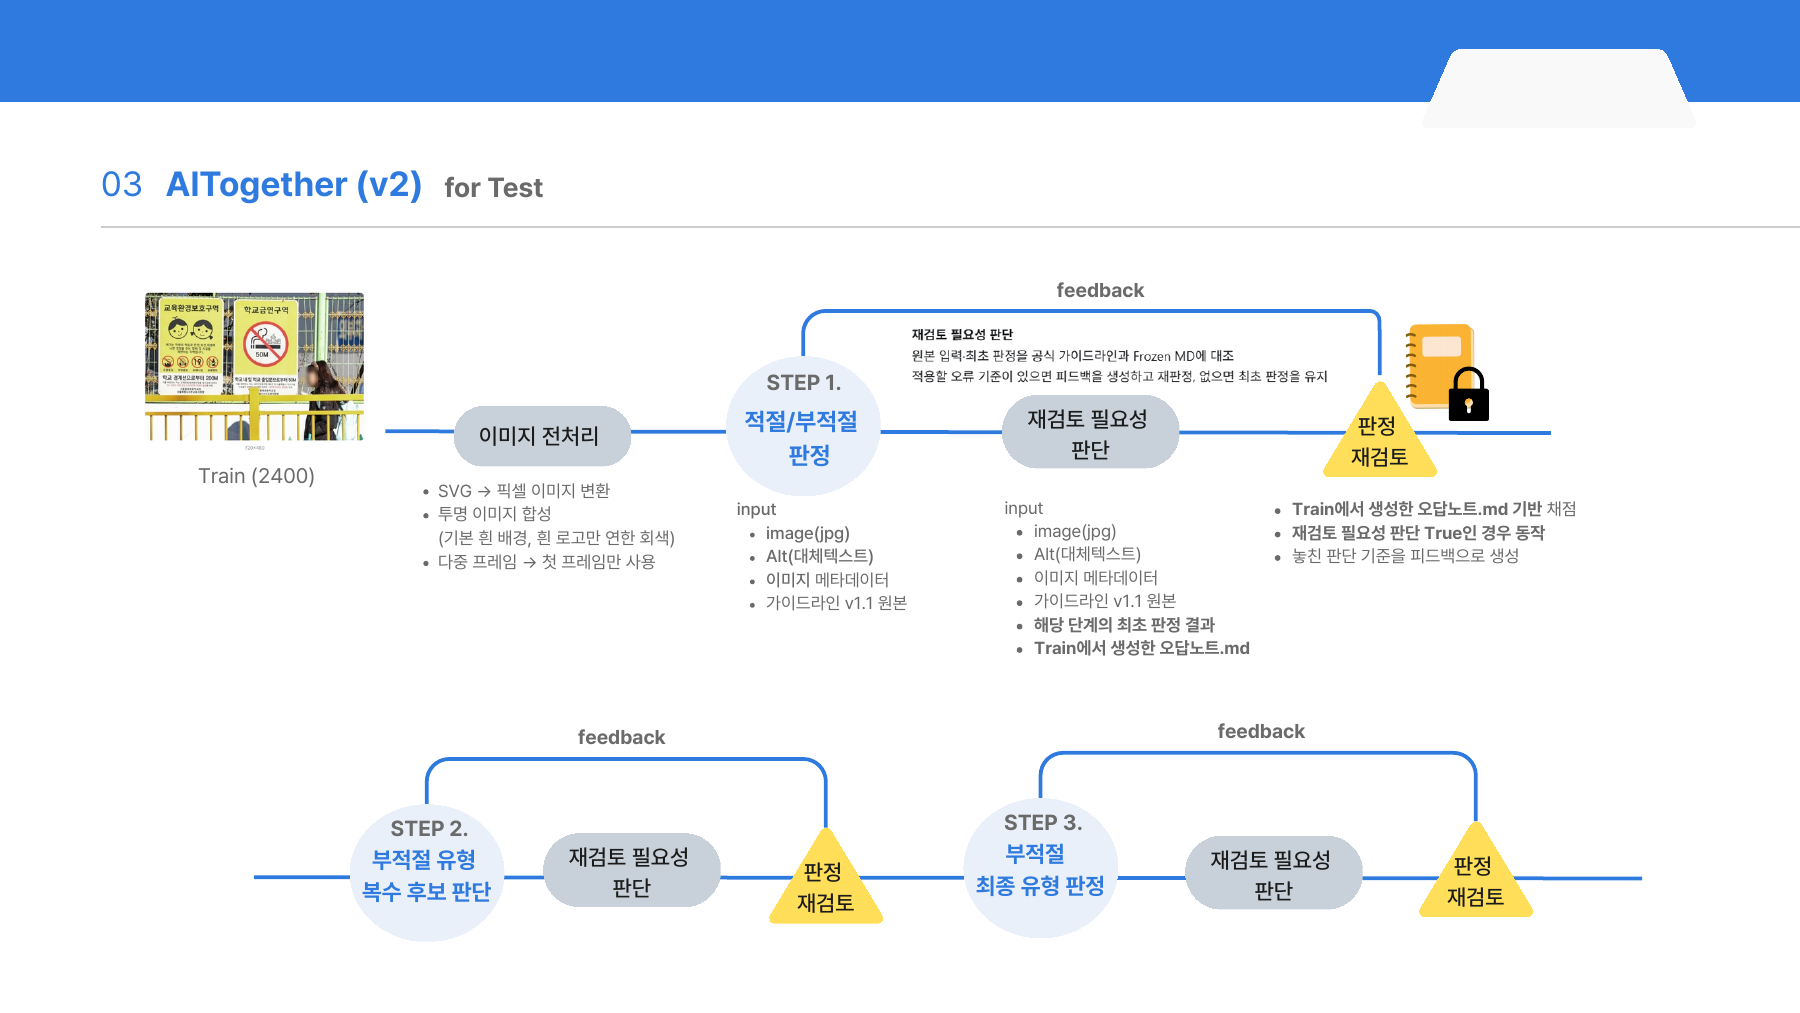

*발표자료 11쪽. 그림의 Train(2,400)은 발표 당시 학습 자료를 정답 없이 다시 평가한 입력이다. 실제 사용에서는 같은 Frozen 절차에 Test 600건을 넣는다. ‘MD 기반 채점’은 정답과의 점수 계산이 아니라 가이드라인에 따른 재검토를 뜻한다.*


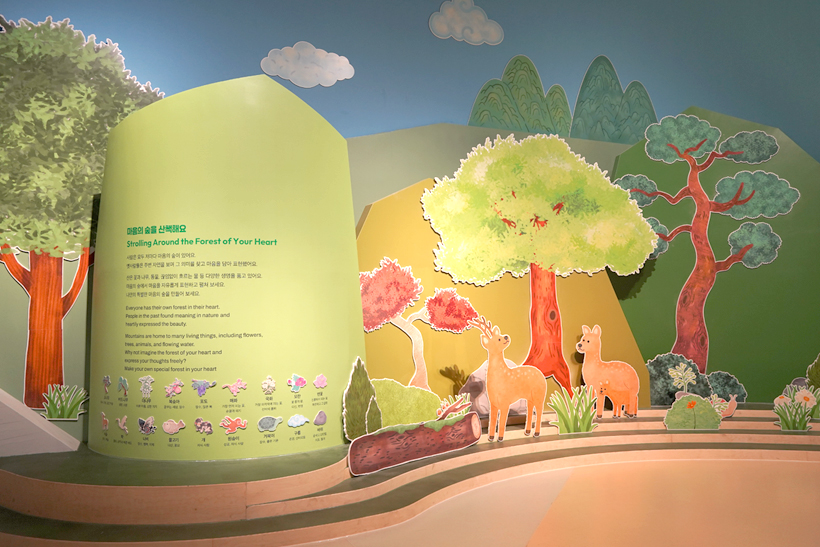

alt: 
binary_decision {
  "verdict": "적절",
  "reason": "이미지는 전시 공간의 전경을 보여주는 현장 사진으로, 주변에 '이전', '다음', '위치 지도'와 같은 내비게이션 텍스트가 존재합니다. 가이드라인의 썸네일 및 사진 판정 기준에 따라, 현장 사진은 장면 제시가 목적이므로 특별한 정보 전달 의무가 없으며, 특히 링크가 아닌 본문 내 이미지로서 alt_text가 빈 값인 경우 이는 장식성 이미지로 처리하여 스크린리더가 낭독하지 않도록 설정한 적절한 조치로 판정합니다.",
  "image_evidence": "어린이박물관 전시 공간의 전경을 찍은 현장 사진으로, 안내 문구가 적힌 전시물과 사슴 모형 등이 배치된 모습임",
  "context_evidence": "페이지 제목이 '상설 전시 > 마음을 이어요'이며, 인접 텍스트로 '이전 다음 위치 지도 내려받기'라는 내비게이션 요소가 확인됨"
}
reflection_feedback {
  "action": "피드백 제공",
  "feedback": "확인 대상: 전시 공간 현장 사진의 정보성 여부 / 현재 전달 근거: 내비게이션 텍스트 존재 및 장면 제시 목적 / 다시 대조할 점: 해당 이미지가 단순 장식인지, 아니면 전시물의 내용(텍스트 포함)과 공간 구성을 전달하는 정보성 이미지로서 고유한 시각 정보를 제공하는지 다시 확인하라.",
  "reason": "링크 밖 빈 alt 이미지의 경우, 단순히 페이지 주제가 있다는 사실만으로 장식성을 인정하지 않는다. 이미지 내에 구체적인 전시 안내 텍스트가 포함되어 있고 공간의 특성을 보여주는 현장 사진이므로, 제거 시 정보 손실이 없는지 재검토가 필요하다."
}
reflection_decision {
  "verdict": "부적절",
  "reason": "이미지는 어린이박물관의 특정 전시 공간('마음을 이어요')의 전경을 보여주는 현장 사진으로, 전시물의 구성, 안내 문구, 입체 조형물 등 고유한 시각 정보를 담고 있는 정

In [7]:
example = next(e for e in examples if e["mode"] == "Frozen" and e["record"]["record_id"] == "r03e65b584e")
from PIL import Image
display(Image.open(ROOT / "demo" / example["image"]))
print("alt:", example["record"]["alt_text"])
for key in ("binary_decision", "reflection_feedback", "reflection_decision", "type_classification", "final_decision", "label"):
    print(key, json.dumps(example["result"].get(key), ensure_ascii=False, indent=2))


In [8]:
RUN_FROZEN = False  # True이면 실제 GPU 추론
if RUN_FROZEN:
    subprocess.run([sys.executable, str(ROOT / "scripts/workflow.py"),
                    "--mode", "frozen", "--dataset", "test", "--limit", "5", "--gpu", "0"], check=True)
else:
    print("Frozen 실행 생략. Test 600건 전체 실행은 --limit 옵션을 제거합니다.")


Frozen 실행 생략. Test 600건 전체 실행은 --limit 옵션을 제거합니다.


## 6. 평가: 공식 Train 및 공개 109건을 분리
Train은 과거 Frozen 실행 `20261028_061912_ce10a3`, 공개 109건은 제출 기반 Test 실행 `20261105_080500_5cf95c`의 보정 전 출력이다.
두 자료의 실행 버전이 다르므로 단순한 성능 차이를 일반화 격차로 해석하지 않는다. 공개 자료는 개선에 활용한 재확인 자료이며 독립 검증셋이 아니다.

In [9]:
for split, file in [("train", "train_frozen_saved.json"), ("public109", "test_frozen_saved.json")]:
    result = evaluate(ROOT / "results" / file, split)
    print(split, {k: result[k] for k in ("count", "binary_f1", "macro_f1", "combined_score", "accuracy")})
    for label, row in result["per_class"].items():
        print(f'  {label}: {row["correct_count"]}/{row["support"]} 정답, F1={row["f1"]:.4f}')


train {'count': 2400, 'binary_f1': 0.8165404775771695, 'macro_f1': 0.7384835741026878, 'combined_score': 0.7775120258399286, 'accuracy': 0.8429166666666666}
  적절: 1384/1599 정답, F1=0.8978
  무의미형: 16/24 정답, F1=0.6531
  파일명형: 26/26 정답, F1=0.8387
  중복형: 127/146 정답, F1=0.8552
  장식오용형: 26/26 정답, F1=0.6500
  불충분형: 432/564 정답, F1=0.7291
  무관형: 12/15 정답, F1=0.5455


public109 {'count': 109, 'binary_f1': 0.7974683544303798, 'macro_f1': 0.2984450923226433, 'combined_score': 0.5479567233765116, 'accuracy': 0.6788990825688074}
  적절: 14/20 정답, F1=0.4667
  무의미형: 0/1 정답, F1=0.0000
  파일명형: 0/0 정답, F1=0.0000
  중복형: 1/1 정답, F1=0.5000
  장식오용형: 1/4 정답, F1=0.3333
  불충분형: 58/83 정답, F1=0.7891
  무관형: 0/0 정답, F1=0.0000


## 7. 공식 제출 성적과 가이드라인 변경 검토
공식 성적은 참가자가 전달한 채점값이다. 위 공개 자료 재평가와 구분한다. 문서를 변경할 때는 교정·악화 사례를 함께 확인하고 새 Frozen 실행으로 비교한다.

In [10]:
score = json.loads((ROOT / "results/official_score.json").read_text(encoding="utf-8"))
print({k: score[k] for k in ("binary_f1", "macro_f1", "combined_score")})
print(score["postprocessing"])
assert abs(score["combined_score"] - .5*(score["binary_f1"]+score["macro_f1"])) < 1e-8


{'binary_f1': 0.8265, 'macro_f1': 0.7035, 'combined_score': 0.765}
해당 제출은 공식 공개 장식오용형 3건 보정 포함. 현재 전체 공개 109건 적용 옵션과 구분.


## 8. 제출 CSV 내보내기
전체 Test가 성공한 실행에서 다음 명령을 사용한다. 공개 정답 후처리는 별도 옵션이다.
```bash
python scripts/export_csv.py --run src/runs/실행_ID --output results/new_submission.csv
# 주최 측이 허용한 공개 109건을 적용하려면 --apply-public-labels 추가
```
단계별 원본 JSON, 피드백, MD와 해시가 실행 폴더에 보존되므로 사람이 결과를 다시 검토할 수 있다.